# Task 1: Data loading, preprocessing and statistical analysis

In [416]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import load_diabetes, load_digits

plt.rcParams.update({"font.size": 12})
pd.set_option("display.precision", 3)

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

## (a) Load the datasets

In [417]:
diabetes = load_diabetes()
df_diab = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df_diab["target"] = diabetes.target
print(f"Features: {list(diabetes.feature_names)}")

digits = load_digits()
df_digits = pd.DataFrame(digits.data, columns=[f"px{i}" for i in range(64)])
df_digits["target"] = digits.target

print("Diabetes shape:", df_diab.shape, "| Digits shape:", df_digits.shape)

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Diabetes shape: (442, 11) | Digits shape: (1797, 65)


## (b) Check for missing, erroneous and outlying values

In [418]:
for name, df in [("Diabetes", df_diab), ("Digits", df_digits)]:
    print(f"{name}: missing values = {df.isna().sum().sum()}, duplicate rows = {df.duplicated().sum()}")

pixels = df_digits.drop(columns="target")
print("Diabetes target range:", df_diab["target"].min(), "to", df_diab["target"].max())
print("Digits pixel range:", pixels.values.min(), "to", pixels.values.max(),
      "| all integers:", bool(np.all(pixels.values % 1 == 0)))
print("Digits constant pixels:", list(pixels.columns[pixels.std() == 0]))
print("Digits images per class:", df_digits["target"].value_counts().sort_index().tolist())

Diabetes: missing values = 0, duplicate rows = 0
Digits: missing values = 0, duplicate rows = 0
Diabetes target range: 25.0 to 346.0
Digits pixel range: 0.0 to 16.0 | all integers: True
Digits constant pixels: ['px0', 'px32', 'px39']
Digits images per class: [178, 182, 177, 183, 181, 182, 181, 179, 174, 180]


In [419]:
features = df_diab.drop(columns="target")
q1, q3 = features.quantile(0.25), features.quantile(0.75)
iqr = q3 - q1
is_outlier = (features < q1 - 1.5 * iqr) | (features > q3 + 1.5 * iqr)
print("IQR outliers per feature:", is_outlier.sum().to_dict())
print("Rows with at least one outlier:", is_outlier.any(axis=1).sum(), "of", len(features))

IQR outliers per feature: {'age': 0, 'sex': 0, 'bmi': 3, 'bp': 0, 's1': 8, 's2': 7, 's3': 7, 's4': 2, 's5': 4, 's6': 9}
Rows with at least one outlier: 31 of 442


Neither dataset has missing or duplicated values, and all values are within valid ranges (pixels are integers from
0 to 16, target is positive). The IQR rule flags 31 of 442 diabetes patients, but these likely result from the skewed features rather than from errors. Removing 7% of a small dataset would cost too much. The digit dataset has three pixels that are always 0 i.e., they carry no information. The ten classes are near evenly distributed (174 to 183 images each).

## (c) Statistical analysis: Diabetes

In [420]:
df_diab.agg(["mean", "std", "min", "max", "nunique", "skew", "kurt"]).T.round(3)

,mean,std,min,max,nunique,skew,kurt
age,-0.000,0.048,-0.107,0.111,58.0,-0.231,-0.671
sex,0.000,0.048,-0.045,0.051,2.0,0.127,-1.993
bmi,-0.000,0.048,-0.090,0.171,163.0,0.598,0.095
bp,-0.000,0.048,-0.112,0.132,100.0,0.291,-0.533
s1,-0.000,0.048,-0.127,0.154,141.0,0.378,0.233
s2,0.000,0.048,-0.116,0.199,302.0,0.437,0.601
s3,-0.000,0.048,-0.102,0.181,63.0,0.799,0.982
s4,-0.000,0.048,-0.076,0.185,66.0,0.735,0.444
s5,0.000,0.048,-0.126,0.134,184.0,0.292,-0.134
s6,0.000,0.048,-0.138,0.136,56.0,0.208,0.237


The features all have mean 0 and the same standard deviation (0.048) because load_diabetes() returns them
already centred and scaled; only the target is in its original units. In raw units, the features
have very different ranges (e.g., age 19 to 79 versus cholesterol 97 to 301), so scaling is needed for the L1/L2 penalties of Lasso and ElasticNet to treat all features equally. The provided data already satisfy this.

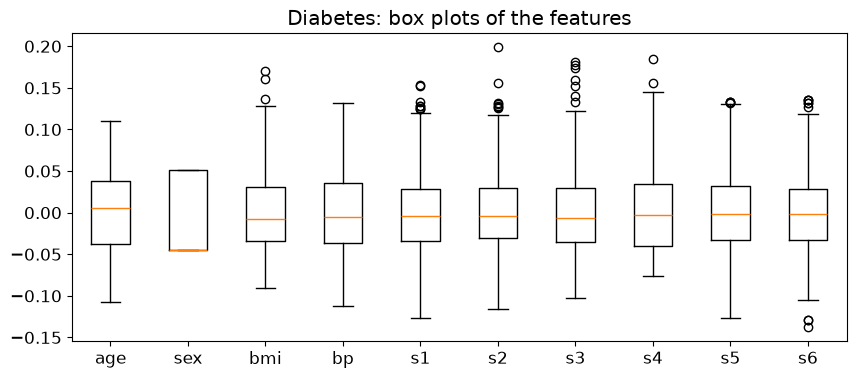

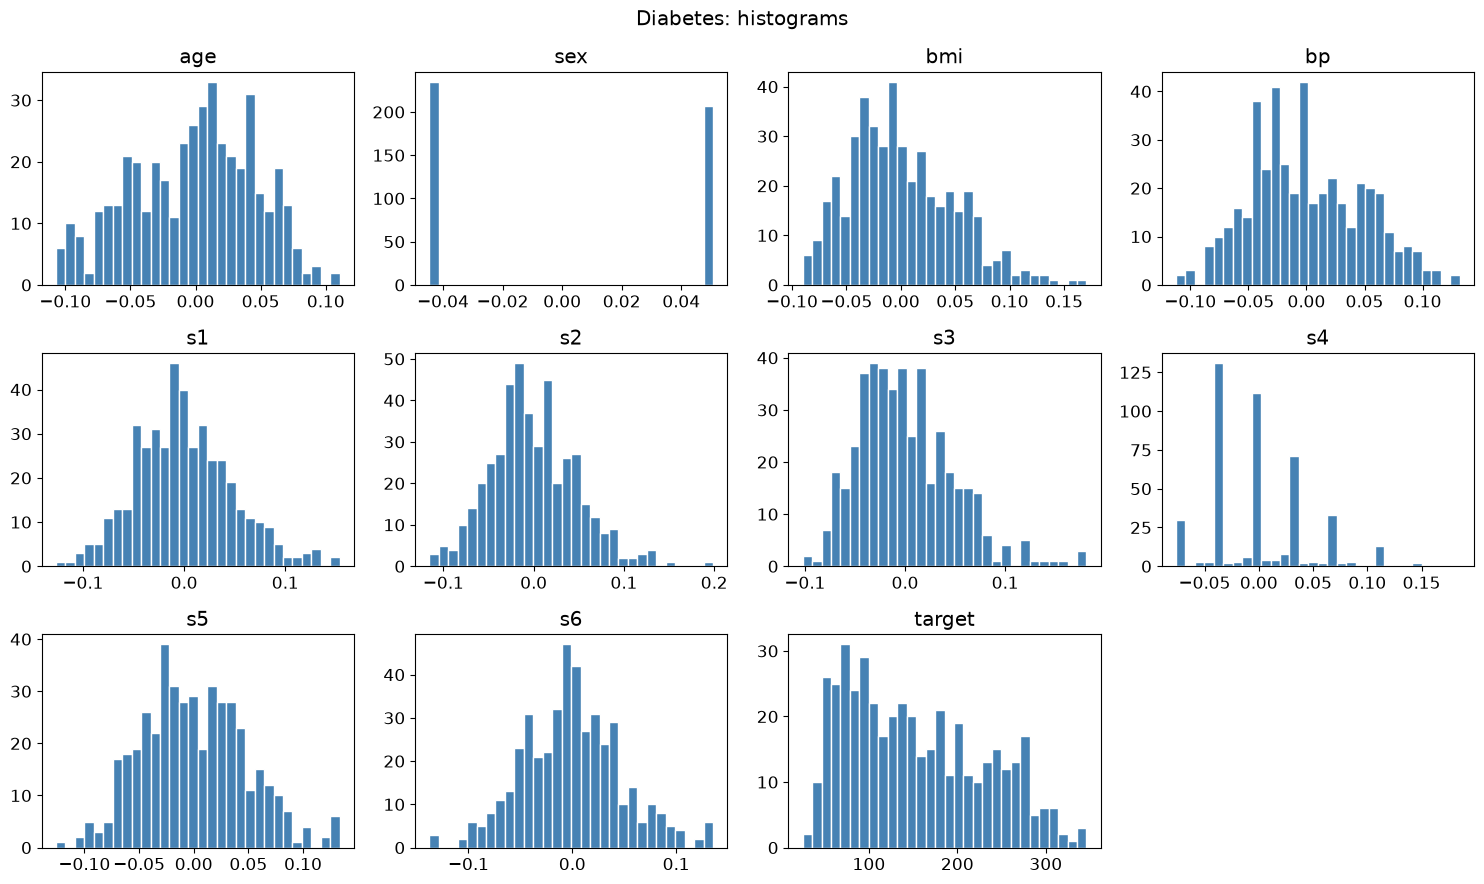

In [421]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(features.values)
ax.set_xticks(range(1, features.shape[1] + 1), features.columns)
ax.set_title("Diabetes: box plots of the features")
fig.savefig(FIG_DIR / "diabetes_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, col in zip(axes.ravel(), df_diab.columns):
    ax.hist(df_diab[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
axes.ravel()[-1].axis("off")
fig.suptitle("Diabetes: histograms")
fig.tight_layout()
fig.savefig(FIG_DIR / "diabetes_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

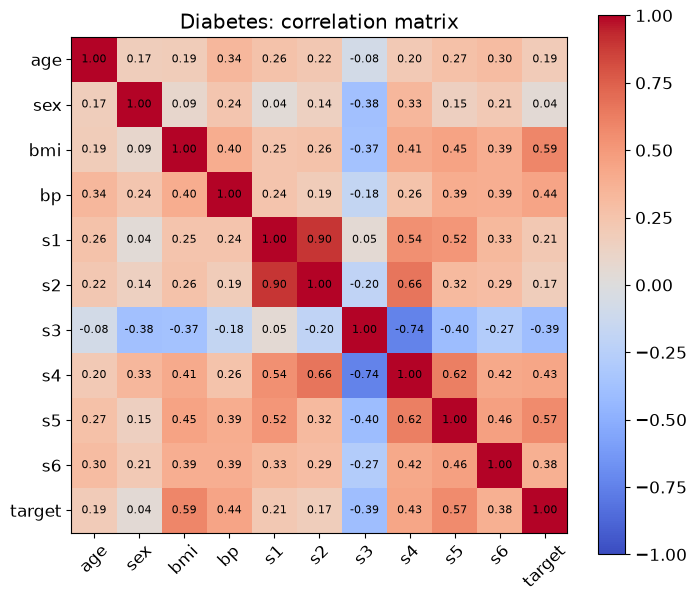

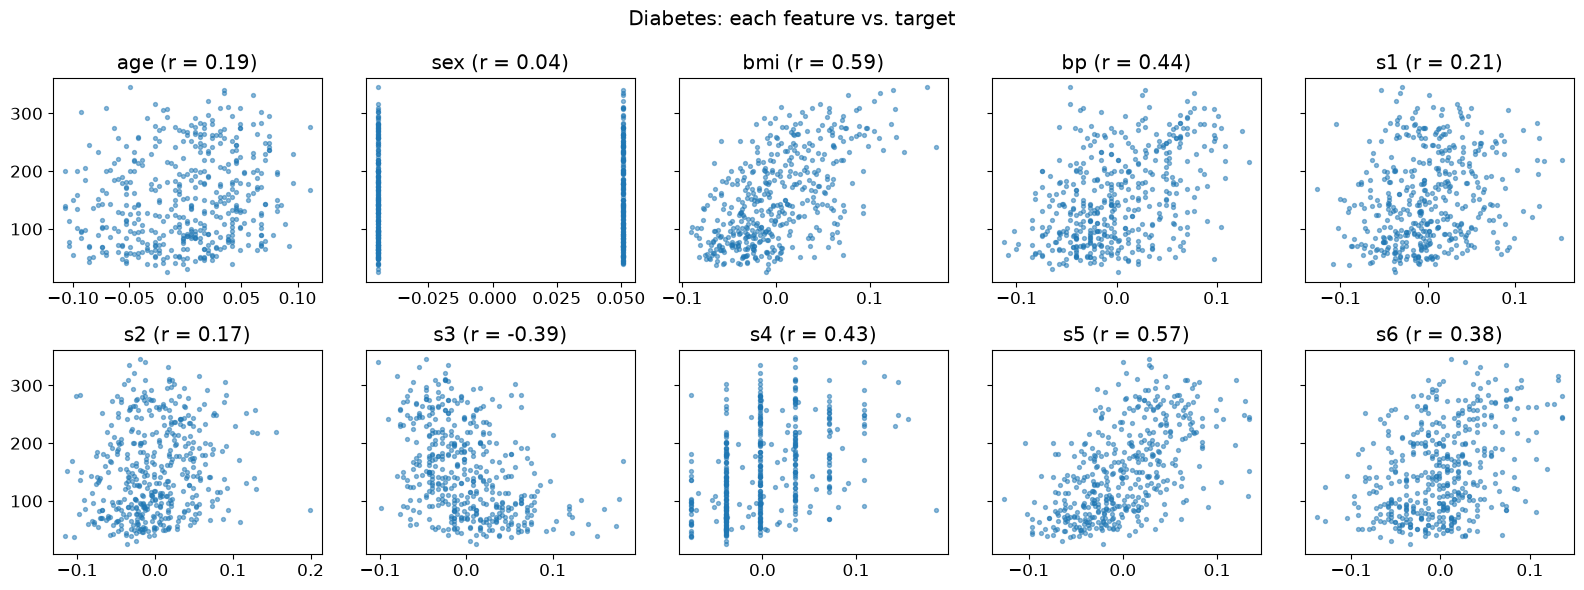

In [422]:
corr = df_diab.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Diabetes: correlation matrix")
fig.savefig(FIG_DIR / "diabetes_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharey=True)
for ax, col in zip(axes.ravel(), features.columns):
    ax.scatter(df_diab[col], df_diab["target"], s=8, alpha=0.5)
    ax.set_title(f"{col} (r = {corr.loc[col, 'target']:.2f})")
fig.suptitle("Diabetes: each feature vs. target")
fig.tight_layout()
fig.savefig(FIG_DIR / "diabetes_feature_vs_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings:** `sex` is a binary feature, and `s4` is almost discrete. Most of '`s4`'s values are rounded. All other variables are continuous and unimodal. `s3`, `s4` and `bmi` are right-skewed (skew 0.6 to 0.8), and the target is also right-skewed. None of the variables are heavy-tailed (Kurtosis < 3), so the distributions are close to Gaussian or have light tails. The features most correlated with the target are `bmi` (0.59) and `s5` (0.57). Some features are strongly correlated with each other: `s1` and
`s2` (0.90) and `s3` and `s4` (−0.74). This is relevant since Lasso tends to keep only one feature from
a correlated group while ElasticNet tends to share the weight between them.

## (c) Statistical analysis: Digits

Pixel means range from 0.00 to 12.09; pixel standard deviations range from 0.00 to 6.54


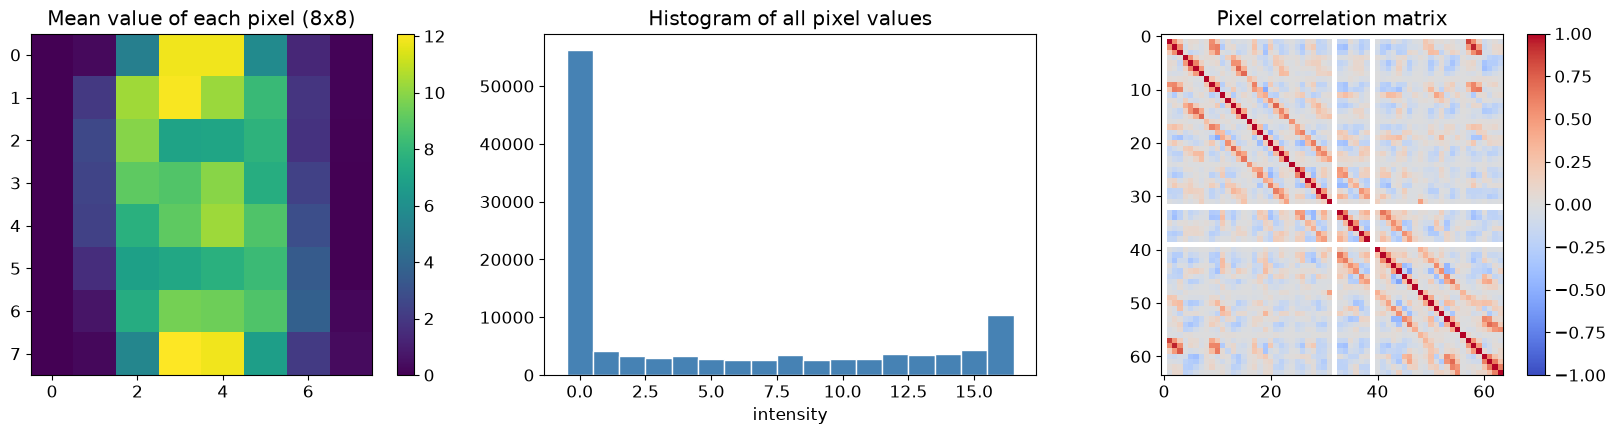

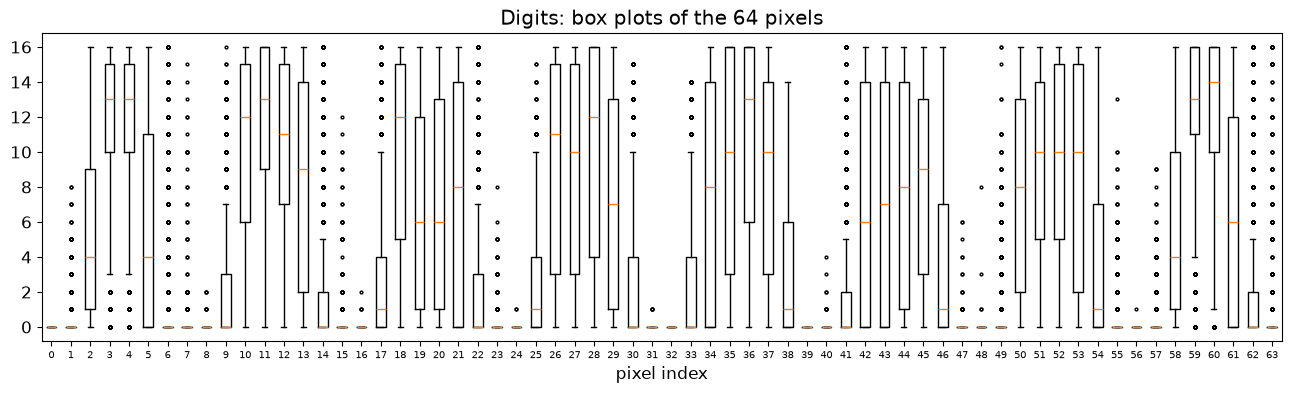

In [423]:
print(f"Pixel means range from {pixels.mean().min():.2f} to {pixels.mean().max():.2f}; "
      f"pixel standard deviations range from {pixels.std().min():.2f} to {pixels.std().max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
im = axes[0].imshow(pixels.mean().values.reshape(8, 8), cmap="viridis")
fig.colorbar(im, ax=axes[0])
axes[0].set_title("Mean value of each pixel (8x8)")

axes[1].hist(pixels.values.ravel(), bins=np.arange(18) - 0.5, color="steelblue", edgecolor="white")
axes[1].set_title("Histogram of all pixel values")
axes[1].set_xlabel("intensity")

im = axes[2].imshow(pixels.corr(), cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[2])
axes[2].set_title("Pixel correlation matrix")
fig.tight_layout()
fig.savefig(FIG_DIR / "digits_summary.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(16, 4))
ax.boxplot(pixels.values, flierprops={"markersize": 2})
ax.set_xticks(range(1, 65), range(64))
ax.tick_params(axis="x", labelsize=7)
ax.set_xlabel("pixel index")
ax.set_title("Digits: box plots of the 64 pixels")
fig.savefig(FIG_DIR / "digits_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings:** All pixels share the same 0 to 16 integer scale, but their means and spreads differ a lot: border
pixels are almost always 0, while central pixels vary over the full range. The pixel values are strongly bimodal,
with about half of them equal to 0 (background) and a second peak at 16 (fully inked). Neighbouring pixels are
positively correlated, which shows up as red bands next to the diagonal of the correlation matrix.

# Task 2.1
## (a) ElasticNet Regression & Lasso Regression

In [424]:
def soft_threshold(z, t):
    return np.sign(z) * np.maximum(np.abs(z) - t, 0)


class ElasticNetRegression:
    """
    Linear regression with combined L1 and L2 regularization and soft thresholding.

    Objective minimized:
        J(W, b) = (1 / 2m) * ||Y - (XW + b)||^2
                  + penalty * ( l1_ratio * ||W||_1
                              + (1 - l1_ratio) / 2 * ||W||_2^2 )

    l1_ratio = 1.0 -> pure Lasso, l1_ratio = 0.0 -> pure Ridge.
    The bias b is not regularized.
    """

    def __init__(self, learning_rate, iterations, penalty, l1_ratio=0.5):
        self.loss_history = None
        self.b = None
        self.W = None
        self.n = None
        self.m = None
        self.Y = None
        self.X = None
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.penalty = penalty
        self.l1_ratio = l1_ratio

    def fit(self, X, Y):
        # training loop
        self.X = np.asarray(X, dtype=float)
        self.Y = np.asarray(Y, dtype=float).ravel()
        self.m, self.n = self.X.shape

        self.W = np.zeros(self.n)
        self.b = 0.0
        self.loss_history = []

        for _ in range(self.iterations):
            self.update_weights()
        return self

    def update_weights(self):
        Y_pred = self.predict(self.X)
        error = self.Y - Y_pred

        mse = (error @ error) / (2 * self.m)
        reg = self.penalty * (
            self.l1_ratio * np.abs(self.W).sum()
            + 0.5 * (1 - self.l1_ratio) * (self.W @ self.W)
        )
        self.loss_history.append(mse + reg)

        dW = -(self.X.T @ error) / self.m + self.penalty * (1 - self.l1_ratio) * self.W
        db = -1 / self.m * error.sum()

        W_step = self.W - self.learning_rate * dW

        threshold = self.learning_rate * self.penalty * self.l1_ratio

        self.W = soft_threshold(W_step, threshold)
        self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.W + self.b

**Note:** Lasso regression is functionally identical to ElasticNet regression with an L1 ratio of 1

## (b) Analysis

In [425]:
test_size = 0.30
seed = 42

(X, y) = df_diab.drop(columns="target").values, df_diab["target"].values

rng = np.random.default_rng(seed)
shuffled_idx = rng.permutation(len(X))

split_idx = int((1 - test_size) * len(X))

train_idx = shuffled_idx[:split_idx]
test_idx = shuffled_idx[split_idx:]

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 309 rows | Test: 133 rows


**i. learning rate / iteration sensitivity**

lr = 1.00e-03, final loss = 7237.56 (ok)
lr = 1.00e-02, final loss = 2850.76 (ok)
lr = 1.00e-01, final loss = 2450.26 (ok)
lr = 1.00e+00, final loss = 2226.21 (ok)
lr = 1.50e+00, final loss = 2226.09 (ok)
lr = 2.00e+00, final loss = 14257.50 (ok)
best lr: 1.50e+00


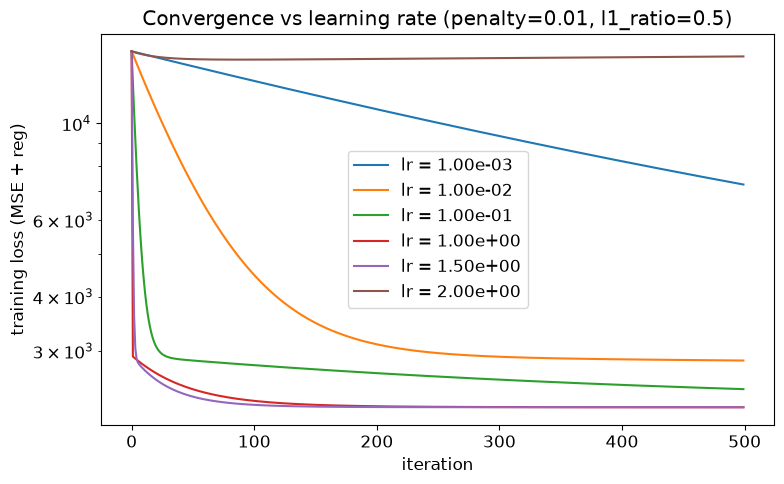

In [426]:
penalty = 0.01
l1_ratio = 0.5
iterations = 500
lr_best, loss_best = None, np.inf

fig, ax = plt.subplots(figsize=(8, 5))
for lr in [1e-3, 1e-2, 1e-1, 1.0, 1.5, 2.0]:
    model = ElasticNetRegression(lr, iterations, penalty, l1_ratio)
    model.fit(X_train, y_train)
    ax.semilogy(model.loss_history, label=f"lr = {lr:.2e}")
    final = model.loss_history[-1]
    status = "ok" if np.isfinite(final) else "diverged"
    print(f"lr = {lr:.2e}, final loss = {final:.2f} ({status})")
    if np.isfinite(final) and final < loss_best:
        loss_best = final
        lr_best = lr

print("best lr:", f"{lr_best:.2e}")

ax.set_xlabel("iteration")
ax.set_ylabel("training loss (MSE + reg)")
ax.set_title(f"Convergence vs learning rate (penalty={penalty}, l1_ratio={l1_ratio})")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "lr_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

**ii) Regularization-path sweep**

In [436]:
def mse(y_true, y_pred):
    err = y_true - y_pred
    return (err @ err) / len(err)


lambdas = np.logspace(-4, 1, 35)
l1_ratios = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
iterations = 10000

# Largest eigenvalue of X^T X / m. The W-stability bound is 2 / (L_X + lambda * (1 - r));
# the bias-stability bound is 2 (its Hessian is 1). We use lr = 1.5 / max(1, L_X + ...)
# so a single step size stays inside both bounds for every (lambda, r) in the sweep.
L_X = np.linalg.eigvalsh(X_train.T @ X_train / len(X_train))[-1]

n_r, n_l = len(l1_ratios), len(lambdas)
W_path = np.zeros((n_r, n_l, X_train.shape[1]))
train_mse = np.zeros((n_r, n_l))
test_mse = np.zeros((n_r, n_l))

for i, r in enumerate(l1_ratios):
    for j, lam in enumerate(lambdas):
        lr = 1.5 / max(1.0, L_X + lam * (1 - r))
        model = ElasticNetRegression(lr, iterations, lam, r)
        model.fit(X_train, y_train)
        W_path[i, j] = model.W
        train_mse[i, j] = mse(y_train, model.predict(X_train))
        test_mse[i, j] = mse(y_test, model.predict(X_test))

best_i, best_j = np.unravel_index(np.argmin(test_mse), test_mse.shape)
print(f"best test MSE = {test_mse[best_i, best_j]:.2f} "
      f"at l1_ratio = {l1_ratios[best_i]:.2f}, lambda = {lambdas[best_j]:.2e}")

best test MSE = 2556.71 at l1_ratio = 1.00, lambda = 2.25e-02


In [428]:
from sklearn.linear_model import LinearRegression, Lasso

r1 = int(np.where(l1_ratios == 1.0)[0][0])

ols = LinearRegression().fit(X_train, y_train)
print(f"OLS test MSE                   : {mse(y_test, ols.predict(X_test)):.2f}")
print(f"ours @ smallest lambda (Lasso) : {test_mse[r1, 0]:.2f}")
print()
print(f"{'alpha':>8}  {'sklearn Lasso':>14}  {'nearest lambda':>14}  {'ours':>10}")
for a in [1e-3, 1e-2, 1e-1, 1.0]:
    sk = Lasso(alpha=a, max_iter=50000).fit(X_train, y_train)
    j = int(np.argmin(np.abs(lambdas - a)))
    print(f"{a:>8.3g}  {mse(y_test, sk.predict(X_test)):>14.2f}  "
          f"{lambdas[j]:>14.3g}  {test_mse[r1, j]:>10.2f}")

OLS test MSE                   : 2538.68
ours @ smallest lambda (Lasso) : 2559.08

   alpha   sklearn Lasso  nearest lambda        ours
   0.001         2539.36         0.00107     2558.87
    0.01         2559.59          0.0115     2557.16
     0.1         2597.46          0.0873     2585.98
       1         3702.67           0.935     3580.76


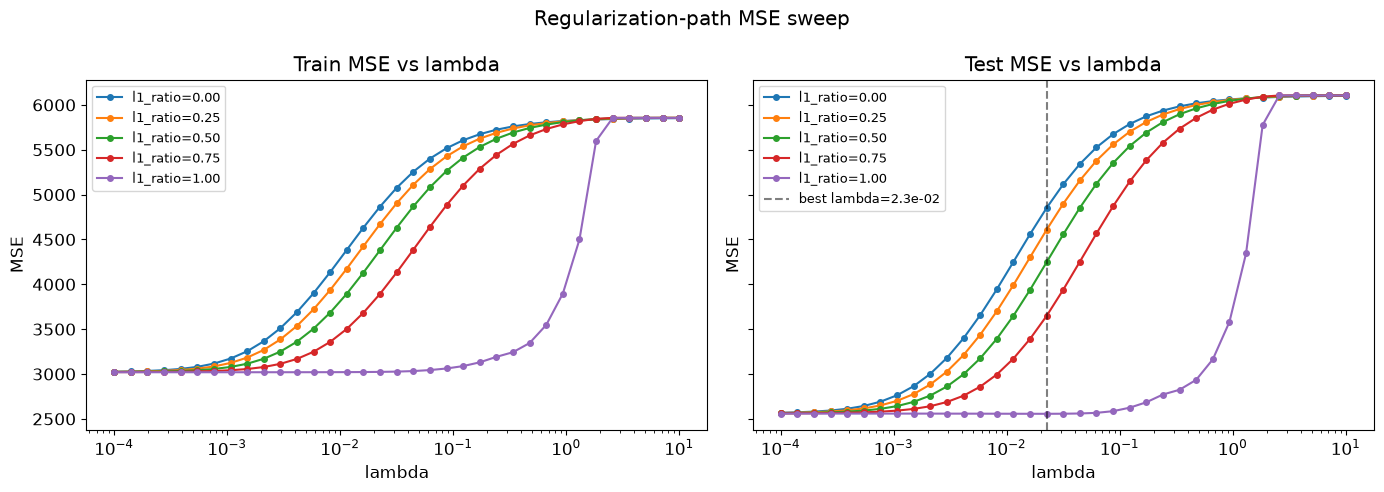

In [429]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for i, r in enumerate(l1_ratios):
    axes[0].semilogx(lambdas, train_mse[i], marker="o", ms=4, label=f"l1_ratio={r:.2f}")
    axes[1].semilogx(lambdas, test_mse[i], marker="o", ms=4, label=f"l1_ratio={r:.2f}")

axes[0].set_title("Train MSE vs lambda")
axes[1].set_title("Test MSE vs lambda")
axes[1].axvline(lambdas[best_j], color="k", linestyle="--", alpha=0.5,
                label=f"best lambda={lambdas[best_j]:.1e}")
for ax in axes:
    ax.set_xlabel("lambda")
    ax.set_ylabel("MSE")
    ax.legend(fontsize=9)
fig.suptitle("Regularization-path MSE sweep")
fig.tight_layout()
fig.savefig(FIG_DIR / "regpath_mse.png", dpi=150, bbox_inches="tight")
plt.show()

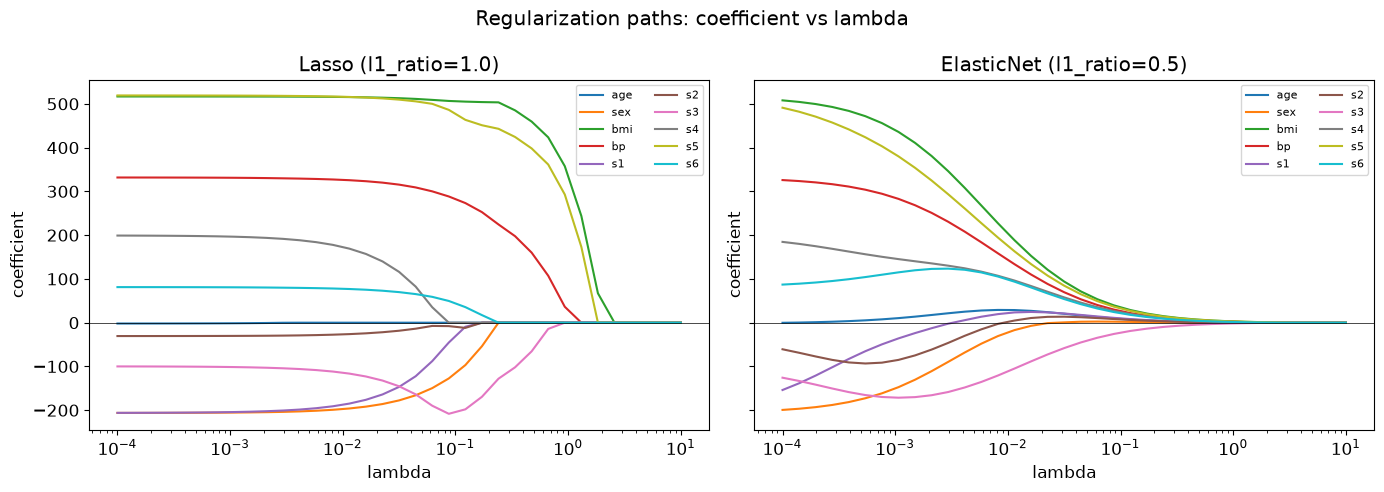

In [430]:
feature_names = df_diab.drop(columns="target").columns.tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, r_idx, title in [
    (axes[0], np.where(l1_ratios == 1.0)[0][0], "Lasso (l1_ratio=1.0)"),
    (axes[1], np.where(l1_ratios == 0.5)[0][0], "ElasticNet (l1_ratio=0.5)"),
]:
    for k, name in enumerate(feature_names):
        ax.semilogx(lambdas, W_path[r_idx, :, k], label=name)
    ax.axhline(0, color="k", linewidth=0.5)
    ax.set_xlabel("lambda")
    ax.set_ylabel("coefficient")
    ax.set_title(title)
    ax.legend(fontsize=8, ncol=2)

fig.suptitle("Regularization paths: coefficient vs lambda")
fig.tight_layout()
fig.savefig(FIG_DIR / "regpath_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

**iii) 5-fold cross-validation**

Picking the best `(lambda, l1_ratio)` on the test set would be peeking. We pick on 5-fold CV
inside the training set and only use the test set to report final MSE.

In [435]:
K = 5
rng_cv = np.random.default_rng(seed)
fold_order = rng_cv.permutation(len(X_train))
folds = np.array_split(fold_order, K)

cv_mse = np.zeros((n_r, n_l))

for i, r in enumerate(l1_ratios):
    for j, lam in enumerate(lambdas):
        lr = 1.5 / max(1.0, L_X + lam * (1 - r))
        fold_errs = np.empty(K)
        for k in range(K):
            val_idx = folds[k]
            tr_idx = np.concatenate([folds[kk] for kk in range(K) if kk != k])
            m_cv = ElasticNetRegression(lr, iterations, lam, r).fit(X_train[tr_idx], y_train[tr_idx])
            fold_errs[k] = mse(y_train[val_idx], m_cv.predict(X_train[val_idx]))
        cv_mse[i, j] = fold_errs.mean()

cv_i, cv_j = np.unravel_index(np.argmin(cv_mse), cv_mse.shape)
r1 = int(np.where(l1_ratios == 1.0)[0][0])
cv_j_lasso = int(np.argmin(cv_mse[r1]))

print(f"CV-best overall : l1_ratio={l1_ratios[cv_i]:.2f}, "
      f"lambda={lambdas[cv_j]:.3g}, CV MSE={cv_mse[cv_i, cv_j]:.2f}")
print(f"CV-best Lasso   : l1_ratio=1.00, "
      f"lambda={lambdas[cv_j_lasso]:.3g}, CV MSE={cv_mse[r1, cv_j_lasso]:.2f}")

CV-best overall : l1_ratio=0.50, lambda=0.000763, CV MSE=3317.97
CV-best Lasso   : l1_ratio=1.00, lambda=0.0873, CV MSE=3335.88


**iv) Final models and coefficient comparison**

Fit the CV-selected Lasso and ElasticNet on all training data, and compare against sklearn's
`LinearRegression`, `Lasso`, and `ElasticNet` on the same split.

In [432]:
from sklearn.linear_model import ElasticNet as SkElasticNet

lam_lasso = lambdas[cv_j_lasso]
lam_en = lambdas[cv_j]
r_en = l1_ratios[cv_i]

lr_lasso = 1.5 / max(1.0, L_X)
lr_en    = 1.5 / max(1.0, L_X + lam_en * (1 - r_en))

final_lasso = ElasticNetRegression(lr_lasso, iterations, lam_lasso, 1.0).fit(X_train, y_train)
final_en    = ElasticNetRegression(lr_en,    iterations, lam_en,    r_en).fit(X_train, y_train)

ols      = LinearRegression().fit(X_train, y_train)
sk_lasso = Lasso(alpha=lam_lasso, max_iter=50000).fit(X_train, y_train)
sk_en    = SkElasticNet(alpha=lam_en, l1_ratio=r_en, max_iter=50000).fit(X_train, y_train)

candidates = {
    "LinearRegression (sklearn)": ols,
    "Lasso (ours)":               final_lasso,
    "Lasso (sklearn)":            sk_lasso,
    "ElasticNet (ours)":          final_en,
    "ElasticNet (sklearn)":       sk_en,
}


def get_coef(m):
    return m.coef_ if hasattr(m, "coef_") else m.W


summary = pd.DataFrame([
    {"model": name,
     "train MSE": mse(y_train, m.predict(X_train)),
     "test MSE":  mse(y_test, m.predict(X_test)),
     "non-zero":  int(np.sum(np.abs(get_coef(m)) > 1e-6))}
    for name, m in candidates.items()
]).set_index("model")

summary.round(2)

,train MSE,test MSE,non-zero
model,,,
LinearRegression (sklearn),3008.73,2538.68,10
Lasso (ours),3061.77,2585.98,8
Lasso (sklearn),3060.86,2584.68,7
ElasticNet (ours),3056.22,2611.84,10
ElasticNet (sklearn),3056.22,2611.84,10


In [433]:
coefs = pd.DataFrame({name: get_coef(m) for name, m in candidates.items()}, index=feature_names)
coefs.round(1)

,LinearRegression (sklearn),Lasso (ours),Lasso (sklearn),ElasticNet (ours),ElasticNet (sklearn)
age,-6.9,0.0,0.0,7.6,7.6
sex,-212.1,-127.4,-127.1,-161.4,-161.4
bmi,506.0,506.7,506.7,456.0,456.0
bp,337.8,288.4,288.2,294.6,294.6
s1,-752.8,-45.4,-57.1,-49.5,-49.6
s2,416.9,-7.8,-0.0,-91.3,-91.3
s3,134.8,-208.2,-203.0,-169.8,-169.7
s4,255.9,0.0,0.0,150.6,150.6
s5,729.9,486.3,492.6,403.2,403.2
s6,74.5,49.6,49.5,109.6,109.6


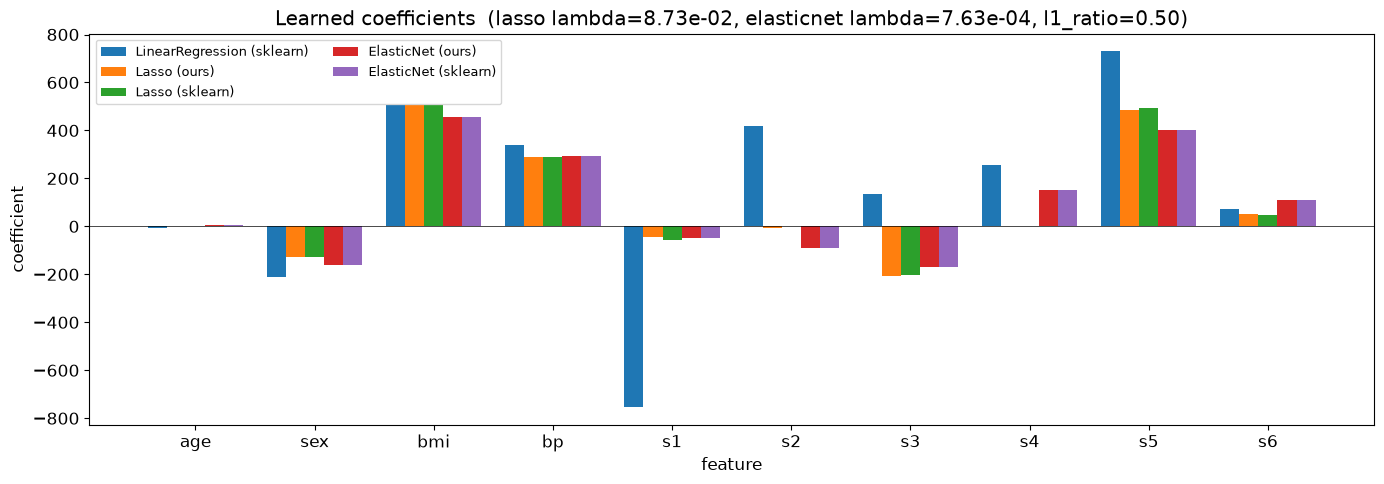

In [434]:
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(feature_names))
width = 0.16
for i, (name, m) in enumerate(candidates.items()):
    ax.bar(x + (i - 2) * width, get_coef(m), width, label=name)
ax.axhline(0, color="k", linewidth=0.5)
ax.set_xticks(x, feature_names)
ax.set_xlabel("feature")
ax.set_ylabel("coefficient")
ax.set_title(f"Learned coefficients  "
             f"(lasso lambda={lam_lasso:.2e}, elasticnet lambda={lam_en:.2e}, l1_ratio={r_en:.2f})")
ax.legend(fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "coefficient_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings.** LinearRegression preserves all coefficients and achieves the lowest train MSE but the highest
test MSE. Lasso at the CV-selected `lambda` selects only a subset of features within the correlated groups flagged in the EDA (`s1`/`s2` at 0.90, `s3`/`s4` at -0.74), as expected with Lasso's tendency to keep only one feature from a correlated pair. ElasticNet shrinks correlated features together instead of dropping one, so its coefficient vector is denser than Lasso's but
has smaller magnitudes. Our implementations reasonably match sklearn's in both test MSE and coefficient values. All regularized models land within a few percent of OLS on test MSE on this split; the value of Lasso and ElasticNet for this dataset is interpretability and sparsity.